In [1]:
import sys
import platform

print("Python version:", sys.version)
print("Platform:", platform.platform())

try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
    else:
        print("GPU unavailable; CPU mode is active.")
except ImportError:
    print("PyTorch is not installed yet.")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch version: 2.11.0+cpu
CUDA available: False
GPU unavailable; CPU mode is active.


In [2]:
import urllib.request
import json

url = "https://zenodo.org/api/records/13843815"

with urllib.request.urlopen(url, timeout=30) as response:
    record = json.loads(response.read().decode("utf-8"))

print("DATASET:", record["metadata"].get("title"))
print("\nFILES AVAILABLE:")

for f in record.get("files", []):
    size_gb = f.get("size", 0) / (1024 ** 3)
    print(f"{f.get('key')} | {size_gb:.3f} GB")

print("\nMetadata check complete.")

DATASET: Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset

FILES AVAILABLE:
STH_and_SM_Dataset_v1_0.zip | 33.485 GB

Metadata check complete.


In [3]:
import urllib.request
import json

url = "https://zenodo.org/api/records/13843815"

with urllib.request.urlopen(url, timeout=30) as response:
    record = json.loads(response.read().decode("utf-8"))

print("Dataset title:")
print(record["metadata"].get("title"))

print("\nDataset description:")
print(record["metadata"].get("description", "No description available"))

print("\nDownload links:")
for f in record.get("files", []):
    print("Filename:", f.get("key"))
    print("Download URL:", f.get("links", {}).get("self"))


Dataset title:
Soil-transmitted Helminths and Schistosoma mansoni Eggs Image Dataset

Dataset description:
<h3><strong>Context</strong></h3>
<p>This dataset was developed as part of the study &ldquo;Deep learning-based automated detection and multiclass classification of soil-transmitted helminths and Schistosoma mansoni eggs in fecal smear images&rdquo; (Oyibo et al., 2025, Scientific Reports).</p>
<p>The work aimed to build a deep learning-ready image dataset to support the automated detection and classification of Soil-transmitted Helminths and Schistosoma mansoni parasite eggs using low-cost digital microscopy. Images were captured using the Schistoscope, a cost-effective automated microscope, and supplemented with the AI4NTD KK2.0 P3.0 STH &amp; SCHm (https://doi.org/10.34740/kaggle/ds/3675429).</p>
<p>The combined dataset addresses limitations of previous collections by improving class balance, incorporating diverse field samples, and supporting AI model development for diagnosti

In [4]:
import requests

url = "https://zenodo.org/api/records/13843815/files/STH_and_SM_Dataset_v1_0.zip/content"

response = requests.get(
    url,
    headers={"Range": "bytes=0-1023"},
    stream=True,
    timeout=30
)

print("HTTP status:", response.status_code)
print("Content-Range:", response.headers.get("Content-Range"))
print("Content-Length:", response.headers.get("Content-Length"))
print("Accept-Ranges:", response.headers.get("Accept-Ranges"))

response.close()

if response.status_code == 206:
    print("Partial access appears supported.")
elif response.status_code == 200:
    print("Server returned HTTP 200; partial access is not confirmed.")
else:
    print("Check the response before proceeding.")

HTTP status: 206
Content-Range: bytes 0-1023/35953708159
Content-Length: 1024
Accept-Ranges: bytes
Partial access appears supported.


In [5]:
!pip -q install remotezip

from remotezip import RemoteZip
from collections import Counter
import requests

url = "https://zenodo.org/api/records/13843815/files/STH_and_SM_Dataset_v1_0.zip/content"

with RemoteZip(url) as zf:
    files = zf.infolist()

    print("Total archive entries:", len(files))

    print("\nJSON annotation files:")
    json_files = [
        f for f in files
        if f.filename.lower().endswith(".json")
    ]

    for f in json_files[:50]:
        print(f.filename, "|", round(f.file_size / (1024**2), 2), "MB")

    print("\nImage file count:")
    image_files = [
        f for f in files
        if f.filename.lower().endswith((".png", ".jpg", ".jpeg"))
    ]
    print(len(image_files))

    print("\nFirst 25 image files:")
    for f in image_files[:25]:
        print(f.filename, "|", round(f.file_size / (1024**2), 3), "MB")

    print("\nTop-level folders:")
    folders = Counter(
        f.filename.split("/")[0]
        for f in files if "/" in f.filename
    )
    for folder, count in folders.most_common(20):
        print(folder, "| entries:", count)

Total archive entries: 21130

JSON annotation files:
STH_and_SM_Dataset_v1_0/annotations/image_00001.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00002.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00003.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00004.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00005.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00006.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00007.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00008.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00009.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00010.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00011.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00012.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00013.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00014.json | 0.0 MB
STH_and_SM_Dataset_v1_0/annotations/image_00015.json | 0.0 MB
STH_and_SM_Datase

In [7]:
!pip -q install remotezip

import os
import json
from pathlib import Path
from remotezip import RemoteZip

URL = (
    "https://zenodo.org/api/records/13843815/files/"
    "STH_and_SM_Dataset_v1_0.zip/content"
)

BASE = "STH_and_SM_Dataset_v1_0"
OUT = Path("/content/helminth_data")
IMG_DIR = OUT / "images"
ANN_DIR = OUT / "annotations"

IMG_DIR.mkdir(parents=True, exist_ok=True)
ANN_DIR.mkdir(parents=True, exist_ok=True)

# Initial smoke test only; not the final research sample.
N = 24

with RemoteZip(URL) as zf:
    available = set(zf.namelist())

    downloaded = 0

    for i in range(1, N + 1):
        name = f"image_{i:05d}"
        image_member = f"{BASE}/images/{name}.png"
        json_member = f"{BASE}/annotations/{name}.json"

        if image_member not in available:
            print("Missing image:", image_member)
            continue

        if json_member not in available:
            print("Missing annotation:", json_member)
            continue

        # Read only the selected archive members.
        for member, destination in [
            (image_member, IMG_DIR / f"{name}.png"),
            (json_member, ANN_DIR / f"{name}.json"),
        ]:
            if not destination.exists():
                with zf.open(member) as src, open(destination, "wb") as dst:
                    while True:
                        chunk = src.read(1024 * 1024)
                        if not chunk:
                            break
                        dst.write(chunk)

        downloaded += 1
        print(f"Processed pair {downloaded}/{N}: {name}")

print("\nImage-annotation pairs available:", downloaded)
print("Local directory:", OUT)

Processed pair 1/24: image_00001
Processed pair 2/24: image_00002
Processed pair 3/24: image_00003
Processed pair 4/24: image_00004
Processed pair 5/24: image_00005
Processed pair 6/24: image_00006
Processed pair 7/24: image_00007
Processed pair 8/24: image_00008
Processed pair 9/24: image_00009
Processed pair 10/24: image_00010
Processed pair 11/24: image_00011
Processed pair 12/24: image_00012
Processed pair 13/24: image_00013
Processed pair 14/24: image_00014
Processed pair 15/24: image_00015
Processed pair 16/24: image_00016
Processed pair 17/24: image_00017
Processed pair 18/24: image_00018
Processed pair 19/24: image_00019
Processed pair 20/24: image_00020
Processed pair 21/24: image_00021
Processed pair 22/24: image_00022
Processed pair 23/24: image_00023
Processed pair 24/24: image_00024

Image-annotation pairs available: 24
Local directory: /content/helminth_data


In [8]:
import json
from pathlib import Path
from collections import Counter
from PIL import Image

BASE = Path("/content/helminth_data")
IMG_DIR = BASE / "images"
ANN_DIR = BASE / "annotations"

files = sorted(ANN_DIR.glob("*.json"))
class_counts = Counter()
total_annotations = 0
valid_pairs = 0

for ann_path in files:
    with open(ann_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    image_path = IMG_DIR / (ann_path.stem + ".png")

    if not image_path.exists():
        print("Missing image:", image_path.name)
        continue

    with Image.open(image_path) as img:
        width, height = img.size

    annotations = data.get("annotations", [])
    categories = data.get("categories", [])

    for item in annotations:
        total_annotations += 1

        # Category names from this JSON file
        category_id = item.get("category_id")
        category = next(
            (c for c in categories if c.get("id") == category_id),
            None
        )
        label = category.get("name", str(category_id)) if category else str(category_id)
        class_counts[label] += 1

    valid_pairs += 1

print("Valid image-annotation pairs:", valid_pairs)
print("Total annotations:", total_annotations)
print("Class counts:", dict(class_counts))

if files:
    with open(files[0], "r", encoding="utf-8") as f:
        example = json.load(f)

    print("\nFirst JSON keys:", list(example.keys()))
    print("First image dimensions:", width, "x", height)
    print("First annotation example:")
    if example.get("annotations"):
        print(example["annotations"][0])
    else:
        print("No annotations in this file.")

Valid image-annotation pairs: 24
Total annotations: 0
Class counts: {}

First JSON keys: ['filename', 'size', 'objects']
First image dimensions: 2028 x 1520
First annotation example:
No annotations in this file.


In [9]:
import json
from pathlib import Path
from pprint import pprint

ANN_DIR = Path("/content/helminth_data/annotations")

json_files = sorted(ANN_DIR.glob("*.json"))

if not json_files:
    print("ERROR: No JSON files found.")
else:
    file_path = json_files[0]

    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print("File:", file_path.name)
    print("\nComplete JSON structure:")
    pprint(data, width=100, sort_dicts=False)

    print("\nNumber of objects:",
          len(data.get("objects", []))
          if isinstance(data.get("objects"), list)
          else "objects is not a list")

File: image_00001.json

Complete JSON structure:
{'filename': 'image_00001.png',
 'size': {'width': 2028, 'height': 1520},
 'objects': [{'label': 'HKW.',
              'bbox': [543.0000118017197, 597.0000147819519, 621.9999722242355, 710.0000095367432],
              'area': 8926.99511337301},
             {'label': 'SCH.',
              'bbox': [1494.999941110611,
                       878.9999628067017,
                       1660.0000405311584,
                       1057.0000267028809],
              'area': 29370.028239733372}]}

Number of objects: 2


In [11]:

import json
from pathlib import Path
from collections import Counter
from PIL import Image

BASE = Path("/content/helminth_data")
IMG_DIR = BASE / "images"
ANN_DIR = BASE / "annotations"

class_counts = Counter()
valid_pairs = 0
total_objects = 0
missing_images = []
invalid_boxes = 0

for ann_path in sorted(ANN_DIR.glob("*.json")):
    image_path = IMG_DIR / f"{ann_path.stem}.png"

    if not image_path.exists():
        missing_images.append(image_path.name)
        continue

    with open(ann_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    with Image.open(image_path) as img:
        image_width, image_height = img.size

    valid_pairs += 1

    for obj in data.get("objects", []):
        label = obj.get("label", "UNKNOWN")
        bbox = obj.get("bbox", [])

        class_counts[label] += 1
        total_objects += 1

        # Expected format: [x_min, y_min, x_max, y_max]
        if len(bbox) != 4:
            invalid_boxes += 1
            continue

        x1, y1, x2, y2 = bbox

        if not (
            0 <= x1 < x2 <= image_width
            and 0 <= y1 < y2 <= image_height
        ):
            invalid_boxes += 1

print("Valid image-annotation pairs:", valid_pairs)
print("Total annotated objects:", total_objects)
print("Class counts:")

for label, count in sorted(class_counts.items()):
    print(f"  {label}: {count}")

print("Invalid bounding boxes:", invalid_boxes)
print("Missing images:", len(missing_images))


Valid image-annotation pairs: 24
Total annotated objects: 61
Class counts:
  HKW.: 45
  SCH.: 16
Invalid bounding boxes: 0
Missing images: 0


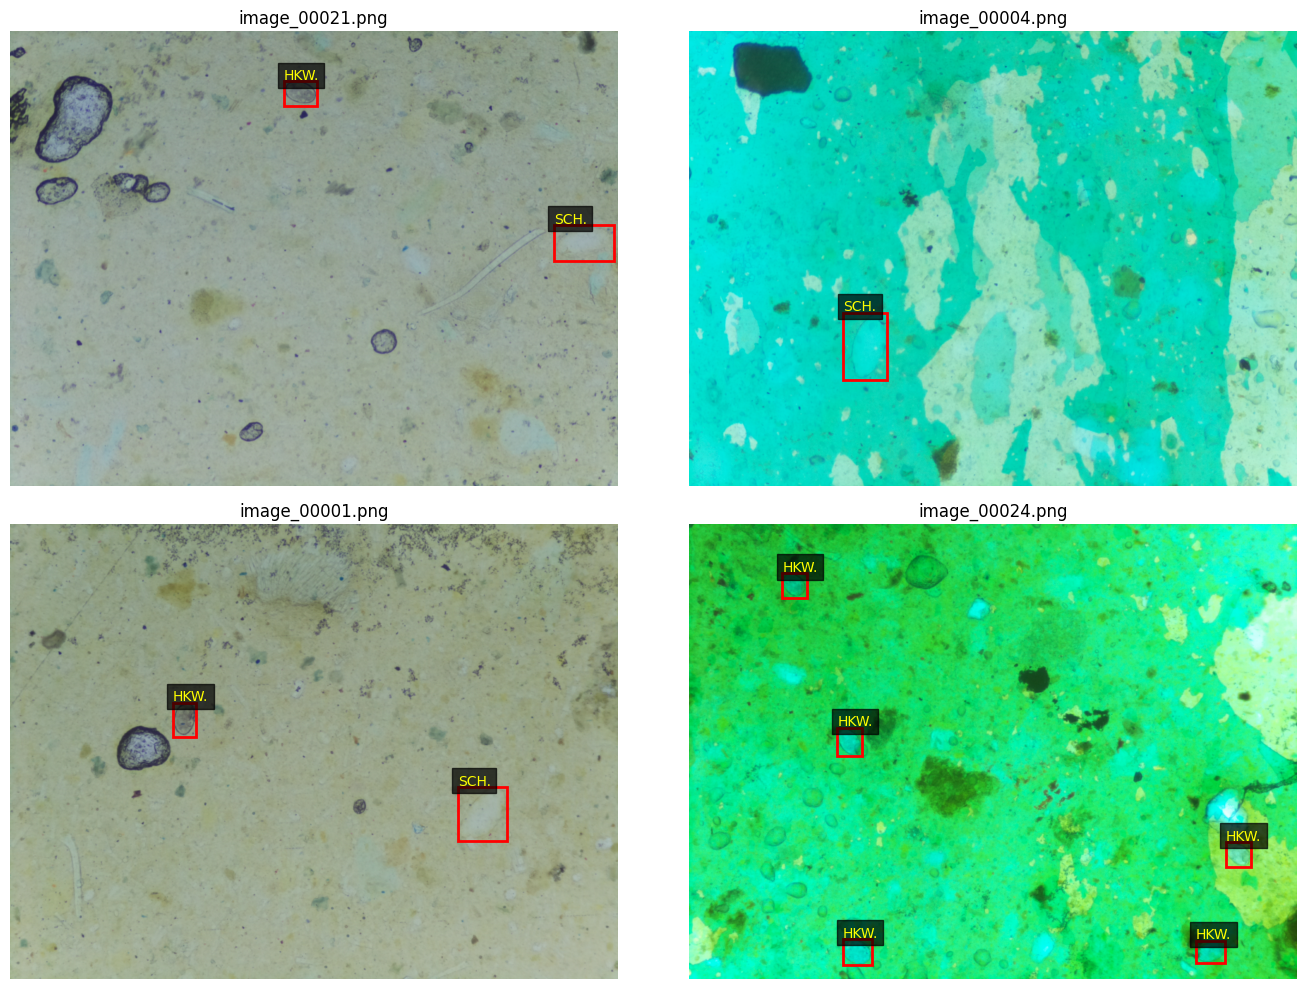

In [12]:

import json
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image

BASE = Path("/content/helminth_data")
IMG_DIR = BASE / "images"
ANN_DIR = BASE / "annotations"

files = sorted(ANN_DIR.glob("*.json"))
random.seed(42)
chosen = random.sample(files, min(4, len(files)))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, ann_path in zip(axes, chosen):
    with open(ann_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    img_path = IMG_DIR / data["filename"]
    img = Image.open(img_path).convert("RGB")
    ax.imshow(img)

    for obj in data.get("objects", []):
        x1, y1, x2, y2 = obj["bbox"]
        rect = patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            linewidth=2, edgecolor="red", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(x1, max(0, y1-8), obj["label"],
                color="yellow", fontsize=10,
                bbox=dict(facecolor="black", alpha=0.7))

    ax.set_title(data["filename"])
    ax.axis("off")

plt.tight_layout()
plt.show()


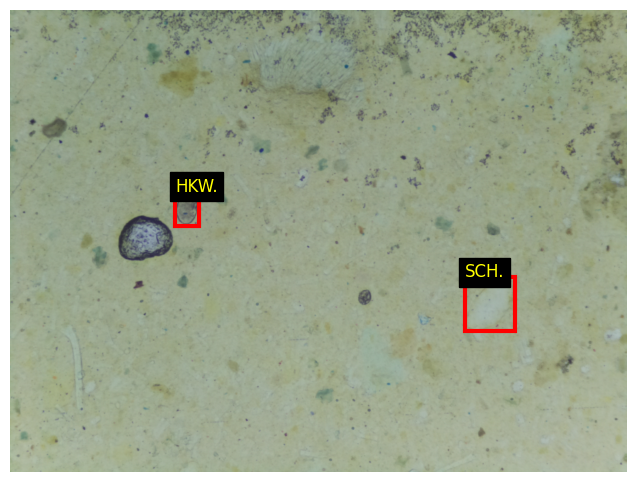

Visualization test complete.


In [13]:

%matplotlib inline

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import json

base = Path("/content/helminth_data")
ann_file = sorted((base / "annotations").glob("*.json"))[0]

with open(ann_file, "r") as f:
    data = json.load(f)

img = Image.open(base / "images" / data["filename"])

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(img)

for obj in data["objects"]:
    x1, y1, x2, y2 = obj["bbox"]
    rect = plt.Rectangle(
        (x1, y1), x2-x1, y2-y1,
        fill=False, edgecolor="red", linewidth=3
    )
    ax.add_patch(rect)
    ax.text(x1, y1, obj["label"], color="yellow",
            fontsize=12, backgroundcolor="black")

ax.axis("off")
plt.show()
print("Visualization test complete.")


In [14]:

!pip -q install ultralytics
print("Ultralytics installation complete.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 7.1 MB/s eta 0:00:00
Ultralytics installation complete.


In [15]:

import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected — CPU training will be slower.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cpu
Ultralytics: 8.4.178
CUDA available: False
GPU not detected — CPU training will be slower.


In [16]:

import json
import random
import shutil
from pathlib import Path
from PIL import Image

random.seed(42)

SOURCE = Path("/content/helminth_data")
OUTPUT = Path("/content/helminth_yolo")

# Two classes confirmed so far in the 24-image sample
class_names = ["HKW.", "SCH."]

if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

for split in ["train", "val"]:
    (OUTPUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT / "labels" / split).mkdir(parents=True, exist_ok=True)

annotations = sorted((SOURCE / "annotations").glob("*.json"))
random.shuffle(annotations)

split_index = max(1, int(len(annotations) * 0.8))
splits = {
    "train": annotations[:split_index],
    "val": annotations[split_index:]
}

for split, files in splits.items():
    for ann_file in files:
        with open(ann_file, "r", encoding="utf-8") as f:
            data = json.load(f)

        image_name = data["filename"]
        src_image = SOURCE / "images" / image_name

        if not src_image.exists():
            continue

        shutil.copy2(src_image, OUTPUT / "images" / split / image_name)

        image = Image.open(src_image)
        width, height = image.size
        image.close()

        label_file = OUTPUT / "labels" / split / f"{ann_file.stem}.txt"

        with open(label_file, "w", encoding="utf-8") as out:
            for obj in data.get("objects", []):
                label = obj.get("label")
                if label not in class_names:
                    continue

                x1, y1, x2, y2 = obj["bbox"]

                # YOLO: class, x_center, y_center, width, height
                x_center = ((x1 + x2) / 2) / width
                y_center = ((y1 + y2) / 2) / height
                box_width = (x2 - x1) / width
                box_height = (y2 - y1) / height

                out.write(
                    f"{class_names.index(label)} "
                    f"{x_center:.6f} {y_center:.6f} "
                    f"{box_width:.6f} {box_height:.6f}\n"
                )

yaml_text = """path: /content/helminth_yolo
train: images/train
val: images/val
names:
  0: HKW.
  1: SCH.
"""

(OUTPUT / "dataset.yaml").write_text(yaml_text, encoding="utf-8")

print("Dataset preparation complete.")
for split in ["train", "val"]:
    image_count = len(list((OUTPUT / "images" / split).glob("*.png")))
    print(f"{split}: {image_count} images")

print("Config:", OUTPUT / "dataset.yaml")


Dataset preparation complete.
train: 19 images
val: 5 images
Config: /content/helminth_yolo/dataset.yaml


In [17]:

from ultralytics import YOLO
import torch

model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/helminth_yolo/dataset.yaml",
    epochs=5,
    imgsz=320,
    batch=2,
    device="cpu",
    workers=0,
    project="/content/helminth_runs",
    name="helminth_prototype",
    exist_ok=True,
    patience=5,
    plots=True
)

print("Training finished.")
print("Best model: /content/helminth_runs/helminth_prototype/weights/best.pt")


Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helminth_yolo/dataset.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helminth_prototype, nbs=64, nms=None, opset=None, opt

Results saved to /content/helminth_runs/validation_predictions


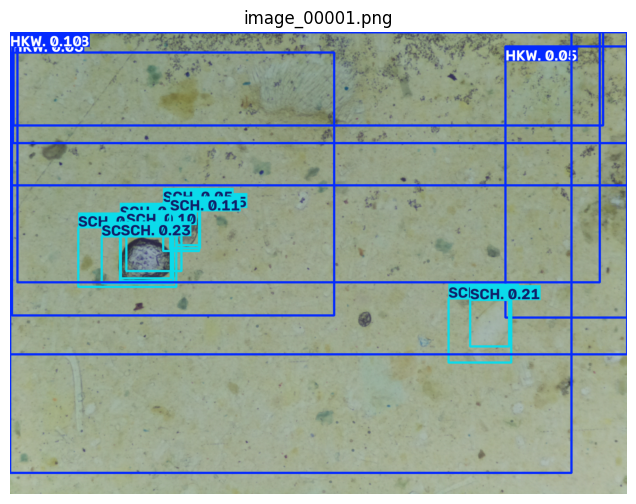

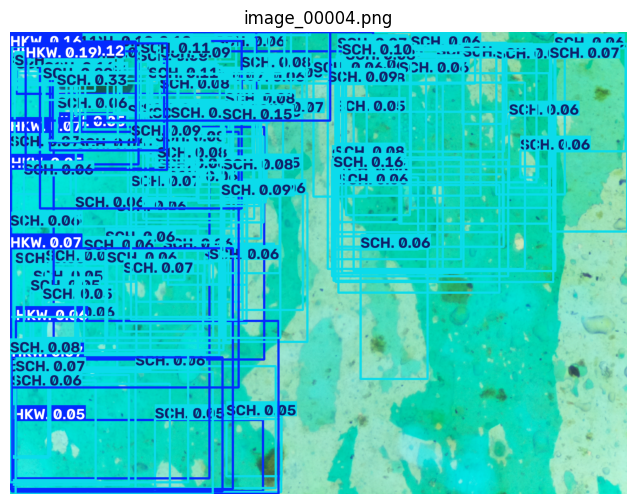

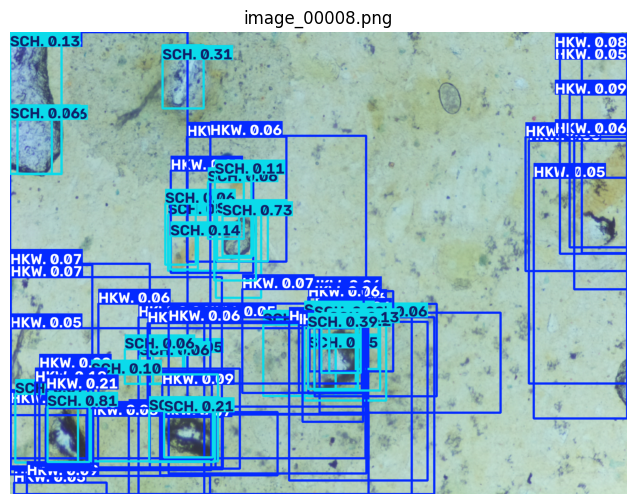

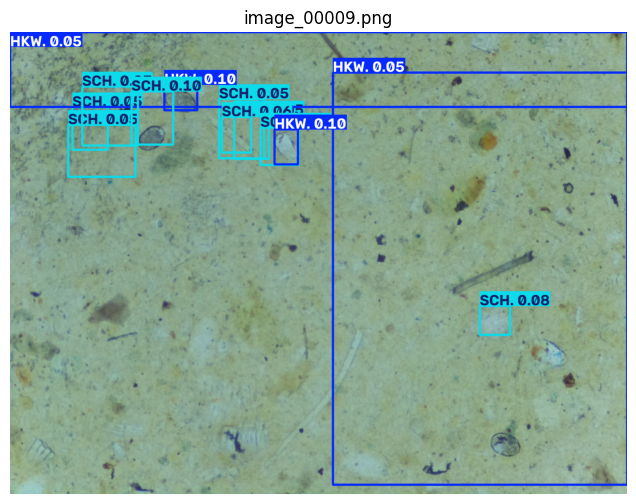

Prediction images saved to:
/content/helminth_runs/validation_predictions


In [18]:

from ultralytics import YOLO
from pathlib import Path
from IPython.display import display
from PIL import Image
import matplotlib.pyplot as plt

model = YOLO(
    "/content/helminth_runs/helminth_prototype/weights/best.pt"
)

val_dir = Path("/content/helminth_yolo/images/val")
image_paths = sorted(val_dir.glob("*.png"))

results = model.predict(
    source=[str(p) for p in image_paths],
    imgsz=320,
    conf=0.05,
    device="cpu",
    save=True,
    project="/content/helminth_runs",
    name="validation_predictions",
    exist_ok=True,
    verbose=False
)

for result in results[:4]:
    plotted = result.plot()
    plt.figure(figsize=(10, 6))
    plt.imshow(plotted[:, :, ::-1])
    plt.title(Path(result.path).name)
    plt.axis("off")
    plt.show()

print("Prediction images saved to:")
print("/content/helminth_runs/validation_predictions")


In [19]:

from pathlib import Path
import shutil
import json

PROJECT = Path("/content/helminth-detection-project")

if PROJECT.exists():
    shutil.rmtree(PROJECT)

(PROJECT / "src").mkdir(parents=True)
(PROJECT / "results").mkdir(parents=True)
(PROJECT / "models").mkdir(parents=True)

readme = """# Helminth Egg Detection Using YOLO11

## Overview
A prototype computer-vision project for detecting annotated
helminth eggs in microscopy images using Ultralytics YOLO11n.

## Current experiment
- Dataset source: https://zenodo.org/records/13843815
- Images used in this prototype: 24
- Training images: 19
- Validation images: 5
- Classes in this sample: HKW. and SCH.
- Epochs: 5
- Image size: 320
- Device: CPU
- Model: YOLO11n pretrained weights

## Preliminary validation results
From this small validation run:
- Precision: 0.0231
- Recall: 0.25
- mAP@50: 0.0319
- mAP@50-95: 0.0124

These results are preliminary and unreliable due to the tiny
sample. They must not be interpreted as clinical performance.
The experiment is a pipeline prototype, not a validated diagnostic tool.

## Dataset preparation
The source dataset is distributed by its authors via Zenodo.
Review the dataset's license and citation requirements before use.
This repository does not redistribute the original dataset.

## Reproduce the prototype
1. Install Python and dependencies.
2. Download the dataset from the source above.
3. Convert per-image JSON `objects` bounding boxes to YOLO labels.
4. Prepare `dataset.yaml`.
5. Train using Ultralytics YOLO11n.

Example training command:
`yolo detect train model=yolo11n.pt data=dataset.yaml epochs=5 imgsz=320 device=cpu`

## Limitations
- Only 24 images were used.
- Only two labels were included in this prototype.
- The validation set contains only five images.
- No independent test set or external validation was performed.
- Not intended for clinical diagnosis.

## Citation
Oyibo et al. (2025), Scientific Reports.
https://doi.org/10.1038/s41598-025-02755-9

Dataset DOI: https://doi.org/10.5281/zenodo.13843815
"""

(PROJECT / "README.md").write_text(readme, encoding="utf-8")

requirements = """ultralytics==8.4.178
torch>=2.0
Pillow
matplotlib
"""

(PROJECT / "requirements.txt").write_text(requirements, encoding="utf-8")

experiment = {
    "model": "YOLO11n",
    "images_total": 24,
    "train_images": 19,
    "validation_images": 5,
    "classes": ["HKW.", "SCH."],
    "epochs": 5,
    "image_size": 320,
    "device": "CPU",
    "validation_metrics": {
        "precision": 0.0231,
        "recall": 0.25,
        "mAP50": 0.0319,
        "mAP50_95": 0.0124
    },
    "limitations": [
        "Very small validation set",
        "Only two classes in the prototype",
        "No independent test set",
        "Not clinically validated"
    ]
}

(PROJECT / "results" / "prototype_metrics.json").write_text(
    json.dumps(experiment, indent=2),
    encoding="utf-8"
)

# Copy trained model weights and prediction images
best = Path("/content/helminth_runs/helminth_prototype/weights/best.pt")
if best.exists():
    shutil.copy2(best, PROJECT / "models" / "best.pt")

predictions = Path("/content/helminth_runs/validation_predictions")
if predictions.exists():
    shutil.copytree(
        predictions,
        PROJECT / "results" / "predictions",
        dirs_exist_ok=True
    )

zip_path = shutil.make_archive(
    "/content/helminth-detection-project",
    "zip",
    root_dir=PROJECT
)

print("Project folder:", PROJECT)
print("ZIP created:", zip_path)
print("Files:")
for path in sorted(PROJECT.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT))


Project folder: /content/helminth-detection-project
ZIP created: /content/helminth-detection-project.zip
Files:
README.md
models/best.pt
requirements.txt
results/predictions/image_00001.jpg
results/predictions/image_00004.jpg
results/predictions/image_00008.jpg
results/predictions/image_00009.jpg
results/predictions/image_00021.jpg
results/prototype_metrics.json


In [20]:

from pathlib import Path
import shutil
from google.colab import files

PROJECT = Path("/content/helminth-detection-project")
SRC = PROJECT / "src"
SRC.mkdir(exist_ok=True)

(SRC / "prepare_dataset.py").write_text(r'''
import json
import random
import shutil
from pathlib import Path
from PIL import Image

SOURCE = Path("/content/helminth_data")
OUTPUT = Path("/content/helminth_yolo")
CLASSES = ["HKW.", "SCH."]

random.seed(42)
if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

annotations = sorted((SOURCE / "annotations").glob("*.json"))
random.shuffle(annotations)
cut = max(1, int(len(annotations) * 0.8))

for split, subset in [
    ("train", annotations[:cut]),
    ("val", annotations[cut:])
]:
    (OUTPUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT / "labels" / split).mkdir(parents=True, exist_ok=True)

    for ann_path in subset:
        data = json.loads(ann_path.read_text(encoding="utf-8"))
        image_path = SOURCE / "images" / data["filename"]
        if not image_path.exists():
            continue

        shutil.copy2(image_path, OUTPUT / "images" / split / image_path.name)

        with Image.open(image_path) as img:
            width, height = img.size

        lines = []
        for obj in data.get("objects", []):
            if obj.get("label") not in CLASSES:
                continue
            x1, y1, x2, y2 = obj["bbox"]
            if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
                continue

            xc, yc = ((x1+x2)/2)/width, ((y1+y2)/2)/height
            bw, bh = (x2-x1)/width, (y2-y1)/height
            lines.append(
                f"{CLASSES.index(obj['label'])} "
                f"{xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
            )

        (OUTPUT / "labels" / split / f"{ann_path.stem}.txt").write_text(
            "\n".join(lines), encoding="utf-8"
        )

(OUTPUT / "dataset.yaml").write_text(
    "path: /content/helminth_yolo\n"
    "train: images/train\n"
    "val: images/val\n"
    "names:\n  0: HKW.\n  1: SCH.\n",
    encoding="utf-8"
)
print("Dataset prepared:", OUTPUT)
''', encoding="utf-8")

(SRC / "train.py").write_text(r'''
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
model.train(
    data="/content/helminth_yolo/dataset.yaml",
    epochs=5,
    imgsz=320,
    batch=2,
    device="cpu",
    workers=0,
    project="/content/helminth_runs",
    name="helminth_prototype",
    exist_ok=True,
    seed=42
)
''', encoding="utf-8")

(SRC / "predict.py").write_text(r'''
from ultralytics import YOLO

model = YOLO("models/best.pt")
model.predict(
    source="/content/helminth_yolo/images/val",
    imgsz=320,
    conf=0.05,
    device="cpu",
    save=True,
    project="runs",
    name="predictions",
    exist_ok=True
)
''', encoding="utf-8")

zip_path = "/content/helminth-detection-project.zip"
Path(zip_path).unlink(missing_ok=True)
shutil.make_archive(
    zip_path.removesuffix(".zip"),
    "zip",
    root_dir=PROJECT
)

size_mb = Path(zip_path).stat().st_size / (1024 * 1024)
print(f"Final ZIP size: {size_mb:.2f} MB")
print("Starting download...")
files.download(zip_path)


Final ZIP size: 8.82 MB
Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:

from pathlib import Path
import shutil

print("Dataset images:", len(list(Path("/content/helminth_data/images").glob("*.png"))))
print("Annotation files:", len(list(Path("/content/helminth_data/annotations").glob("*.json"))))

model_path = Path("/content/helminth_runs/helminth_prototype/weights/best.pt")
project_zip = Path("/content/helminth-detection-project.zip")

print("Trained model exists:", model_path.exists())
print("Project ZIP exists:", project_zip.exists())

if project_zip.exists():
    print("Project ZIP size (MB):", round(project_zip.stat().st_size / (1024 * 1024), 2))

total, used, free = shutil.disk_usage("/content")
print("Free Colab storage (GB):", round(free / (1024**3), 2))


Dataset images: 24
Annotation files: 24
Trained model exists: True
Project ZIP exists: True
Project ZIP size (MB): 8.82
Free Colab storage (GB): 86.95


In [22]:

!pip -q install remotezip

import json
import random
from collections import Counter
from remotezip import RemoteZip

URL = (
    "https://zenodo.org/api/records/13843815/files/"
    "STH_and_SM_Dataset_v1_0.zip/content"
)

BASE = "STH_and_SM_Dataset_v1_0"
random.seed(42)

with RemoteZip(URL) as zf:
    json_files = [
        name for name in zf.namelist()
        if name.startswith(BASE + "/annotations/")
        and name.endswith(".json")
    ]

    sample_files = random.sample(json_files, min(100, len(json_files)))
    class_counts = Counter()
    images_with_objects = 0

    for i, name in enumerate(sample_files, 1):
        with zf.open(name) as f:
            data = json.load(f)

        objects = data.get("objects", [])
        if objects:
            images_with_objects += 1

        for obj in objects:
            class_counts[obj.get("label", "UNKNOWN")] += 1

        if i % 25 == 0:
            print(f"Checked {i}/{len(sample_files)} annotation files")

print("\nRandom sample size:", len(sample_files))
print("Images containing annotations:", images_with_objects)
print("Egg/object counts by label:")
for label, count in sorted(class_counts.items()):
    print(f"{label}: {count}")


Checked 25/100 annotation files
Checked 50/100 annotation files
Checked 75/100 annotation files
Checked 100/100 annotation files

Random sample size: 100
Images containing annotations: 100
Egg/object counts by label:
ASC.: 86
HKW.: 34
SCH.: 42
TRI.: 39


In [23]:

!pip -q install remotezip

import json
import random
import shutil
from pathlib import Path
from remotezip import RemoteZip

URL = (
    "https://zenodo.org/api/records/13843815/files/"
    "STH_and_SM_Dataset_v1_0.zip/content"
)
BASE = "STH_and_SM_Dataset_v1_0"
OUT = Path("/content/helminth_4class")
CLASSES = ["ASC.", "HKW.", "SCH.", "TRI."]

random.seed(42)

if OUT.exists():
    shutil.rmtree(OUT)

for split in ["train", "val", "test"]:
    (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)

with RemoteZip(URL) as zf:
    members = set(zf.namelist())
    annotation_names = sorted(
        n for n in members
        if n.startswith(BASE + "/annotations/")
        and n.endswith(".json")
    )
    random.shuffle(annotation_names)

    # Scan until 400 images with annotations are selected.
    selected = []
    for ann_name in annotation_names:
        with zf.open(ann_name) as f:
            data = json.load(f)

        if any(obj.get("label") in CLASSES for obj in data.get("objects", [])):
            selected.append((ann_name, data))

        if len(selected) >= 400:
            break

    print("Selected annotated images:", len(selected))

    # Split by image before converting annotations.
    n = len(selected)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    split_items = {
        "train": selected[:n_train],
        "val": selected[n_train:n_train+n_val],
        "test": selected[n_train+n_val:]
    }

    for split, items in split_items.items():
        for i, (ann_name, data) in enumerate(items, 1):
            image_name = data["filename"]
            image_member = f"{BASE}/images/{image_name}"

            with zf.open(image_member) as src:
                image_bytes = src.read()

            image_path = OUT / "images" / split / image_name
            image_path.write_bytes(image_bytes)

            # Save per-image annotation temporarily for auditability.
            (OUT / "labels" / split / f"{Path(image_name).stem}.json").write_text(
                json.dumps(data, indent=2), encoding="utf-8"
            )

            if i % 50 == 0:
                print(f"{split}: {i}/{len(items)} images extracted")

print("\nExtraction complete.")
for split in ["train", "val", "test"]:
    print(split, "images:", len(list((OUT / "images" / split).glob("*.png"))))
print("Dataset location:", OUT)


Selected annotated images: 400
train: 50/280 images extracted
train: 100/280 images extracted
train: 150/280 images extracted
train: 200/280 images extracted
train: 250/280 images extracted
val: 50/60 images extracted
test: 50/60 images extracted

Extraction complete.
train images: 280
val images: 60
test images: 60
Dataset location: /content/helminth_4class


In [24]:

import json
from pathlib import Path
from collections import Counter

import yaml

OUT = Path("/content/helminth_4class")
CLASSES = ["ASC.", "HKW.", "SCH.", "TRI."]

counts = Counter()
total = 0

for split in ["train", "val", "test"]:
    for ann_path in sorted((OUT / "labels" / split).glob("*.json")):
        data = json.loads(ann_path.read_text(encoding="utf-8"))
        w = data["size"]["width"]
        h = data["size"]["height"]
        lines = []

        for obj in data.get("objects", []):
            label = obj.get("label")
            if label not in CLASSES:
                continue

            x1, y1, x2, y2 = obj["bbox"]
            if not (0 <= x1 < x2 <= w and 0 <= y1 < y2 <= h):
                continue

            xc, yc = ((x1+x2)/2)/w, ((y1+y2)/2)/h
            bw, bh = (x2-x1)/w, (y2-y1)/h
            lines.append(
                f"{CLASSES.index(label)} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
            )
            counts[(split, label)] += 1
            total += 1

        txt_path = OUT / "labels" / split / f"{ann_path.stem}.txt"
        txt_path.write_text("\n".join(lines), encoding="utf-8")
        ann_path.unlink()

config = {
    "path": str(OUT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: name for i, name in enumerate(CLASSES)}
}
(OUT / "dataset.yaml").write_text(
    yaml.safe_dump(config, sort_keys=False), encoding="utf-8"
)

print("YOLO dataset prepared.")
for split in ["train", "val", "test"]:
    print(split, "images:", len(list((OUT / "images" / split).glob("*.png"))))
print("Total valid objects:", total)
print("Class counts by split:")
for key, value in sorted(counts.items()):
    print(key, value)


YOLO dataset prepared.
train images: 280
val images: 60
test images: 60
Total valid objects: 805
Class counts by split:
('test', 'ASC.') 45
('test', 'HKW.') 21
('test', 'SCH.') 25
('test', 'TRI.') 22
('train', 'ASC.') 242
('train', 'HKW.') 129
('train', 'SCH.') 110
('train', 'TRI.') 94
('val', 'ASC.') 50
('val', 'HKW.') 20
('val', 'SCH.') 20
('val', 'TRI.') 27


In [25]:

import json
from pathlib import Path
from collections import Counter
import yaml

OUT = Path("/content/helminth_4class")
CLASSES = ["ASC.", "HKW.", "SCH.", "TRI."]
counts = Counter()

for split in ["train", "val", "test"]:
    for ann in sorted((OUT / "labels" / split).glob("*.json")):
        data = json.loads(ann.read_text())
        w, h = data["size"]["width"], data["size"]["height"]
        lines = []

        for obj in data.get("objects", []):
            label = obj.get("label")
            if label not in CLASSES:
                continue

            x1, y1, x2, y2 = obj["bbox"]
            if not (0 <= x1 < x2 <= w and 0 <= y1 < y2 <= h):
                continue

            xc, yc = ((x1+x2)/2)/w, ((y1+y2)/2)/h
            bw, bh = (x2-x1)/w, (y2-y1)/h
            lines.append(
                f"{CLASSES.index(label)} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
            )
            counts[(split, label)] += 1

        (OUT / "labels" / split / f"{ann.stem}.txt").write_text(
            "\n".join(lines)
        )
        ann.unlink()

config = {
    "path": str(OUT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: name for i, name in enumerate(CLASSES)}
}
(OUT / "dataset.yaml").write_text(yaml.safe_dump(config, sort_keys=False))

print("YOLO dataset prepared.")
for split in ["train", "val", "test"]:
    print(split, "images:", len(list((OUT / "images" / split).glob("*.png"))))
print("\nObject counts:")
for (split, label), count in sorted(counts.items()):
    print(f"{split:5} | {label:5} | {count}")
print("\nConfig:", OUT / "dataset.yaml")


YOLO dataset prepared.
train images: 280
val images: 60
test images: 60

Object counts:

Config: /content/helminth_4class/dataset.yaml


In [26]:

from ultralytics import YOLO

model = YOLO("yolo11n.pt")

model.train(
    data="/content/helminth_4class/dataset.yaml",
    epochs=15,
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    project="/content/helminth_runs",
    name="helminth_4class",
    exist_ok=True,
    seed=42,
    plots=True,
    patience=5
)

print("4-class training complete.")
print("Best model: /content/helminth_runs/helminth_4class/weights/best.pt")


Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helminth_4class/dataset.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helminth_4class, nbs=64, nms=None, opset=None, opt

In [27]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

source = "/content/helminth_runs/helminth_4class"
destination = "/content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training"

os.makedirs(os.path.dirname(destination), exist_ok=True)
shutil.copytree(source, destination, dirs_exist_ok=True)

print("Training backup saved to Google Drive.")
print("Best model:", os.path.join(destination, "weights", "best.pt"))
print("Model exists:", os.path.exists(os.path.join(destination, "weights", "best.pt")))

Mounted at /content/drive
Training backup saved to Google Drive.
Best model: /content/drive/MyDrive/Helminth_Project_Backup/helminth_4class_training/weights/best.pt
Model exists: True
